# 04 — OLS regressions

Is the foreign share associated with federal income tax per resident and with the social assistance rate, once we compare communes that are similar in size, density, age structure, jobs, urban type and canton?

Input: `data/processed/communes_2022.csv`. Output: `Results/regressions/`.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
sys.path.append("../code")
import helpers

df, tax_sample, sa_sample = helpers.load_model_samples()
OUT = helpers.results_dir("regressions")

print("Tax models:", len(tax_sample), "communes")
print("SA models: ", len(sa_sample), "communes")

Tax models: 2108 communes
SA models:  1625 communes


In [2]:
# How the samples are built (for the data section of the paper)
steps = {
    "All communes (list of 6 April 2025)": df,
    "Tax models: no missing explanatory variable": tax_sample,
    "SA models: social assistance rate also reported": sa_sample,
}
table_sample = pd.DataFrame({
    "Communes": {step: len(data) for step, data in steps.items()},
    "Population covered (%)": {step: 100 * data["population"].sum() / df["population"].sum()
                               for step, data in steps.items()},
})
table_sample["Dropped at this step"] = (-table_sample["Communes"].diff()).fillna("")
table_sample = table_sample.round(1)
table_sample.to_csv(OUT / "table_sample_construction.csv")
table_sample

,Communes,Population covered (%),Dropped at this step
All communes (list of 6 April 2025),2115,100.0,
Tax models: no missing explanatory variable,2108,100.0,7.0
SA models: social assistance rate also reported,1625,95.8,483.0


## 1. The simplest model: tax and foreign share only

In [3]:
m0 = smf.ols("log_tax ~ foreign_share", data=tax_sample).fit()
print(m0.summary())

(OUT / "m0_tax_simple.txt").write_text(m0.summary().as_text())

                            OLS Regression Results                            
Dep. Variable:                log_tax   R-squared:                       0.087
Model:                            OLS   Adj. R-squared:                  0.086
Method:                 Least Squares   F-statistic:                     200.4
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.57e-43
Time:                        13:09:40   Log-Likelihood:                -2018.6
No. Observations:                2108   AIC:                             4041.
Df Residuals:                    2106   BIC:                             4053.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         6.4336      0.029    225.654

1852

**Interpretation.** Without controls, one percentage point more foreign residents goes with about 2% higher federal income tax per resident (coefficient 0.0199). Foreign share alone explains only 9% of the differences in tax between communes (R² = 0.087). The standard errors here assume communes are independent; the Durbin-Watson statistic (1.39 < 2) suggests neighbouring communes have similar errors, so from now on standard errors are clustered by canton.

## 2. Adding controls step by step (M1 → M4)

In [4]:
import warnings
# With canton fixed effects and only 26 canton clusters, statsmodels cannot compute
# the overall F-test; it warns about it. The coefficients and their SEs are unaffected.
warnings.filterwarnings("ignore", message="covariance of constraints does not have full rank")

size_age_jobs = "log_population + log_density + share_under20 + share_65plus + jobs_per_capita"

formulas = {
    "M1": "log_tax ~ foreign_share",
    "M2": f"log_tax ~ foreign_share + {size_age_jobs}",
    "M3": f"log_tax ~ foreign_share + {size_age_jobs} + C(urban_rural) + C(language)",
    "M4": f"log_tax ~ {helpers.M4_CONTROLS}",
}

# Communes in the same canton are not independent: cluster the standard errors by canton
clusters = pd.factorize(tax_sample["canton"])[0]

tax_models = {}
for name, formula in formulas.items():
    tax_models[name] = smf.ols(formula, data=tax_sample).fit(
        cov_type="cluster", cov_kwds={"groups": clusters}, use_t=True)
    _ = (OUT / f"tax_{name}.txt").write_text(tax_models[name].summary().as_text())


stars = helpers.stars


def compare(models, variable="foreign_share"):
    """One column per model: coefficient of `variable`, its SE, R² and N."""
    rows = {}
    for name, m in models.items():
        rows[name] = {
            "coefficient": f"{m.params[variable]:.4f}{stars(m.pvalues[variable])}",
            "std. error": f"({m.bse[variable]:.4f})",
            "R²": f"{m.rsquared:.3f}",
            "N": int(m.nobs),
        }
    return pd.DataFrame(rows)


table_tax = compare(tax_models)
table_tax.loc["Size, age, jobs"] = ["no", "yes", "yes", "yes"]
table_tax.loc["Urban type, language"] = ["no", "no", "yes", "yes"]
table_tax.loc["Canton fixed effects"] = ["no", "no", "no", "yes"]
table_tax.to_csv(OUT / "table_tax_M1_M4.csv")
table_tax

,M1,M2,M3,M4
coefficient,0.0199***,0.0138*,0.0094,0.0002
std. error,(0.0054),(0.0077),(0.0069),(0.0055)
R²,0.087,0.191,0.211,0.401
N,2108,2108,2108,2108
"Size, age, jobs",no,yes,yes,yes
"Urban type, language",no,no,yes,yes
Canton fixed effects,no,no,no,yes


**Interpretation.** The foreign-share coefficient shrinks as controls are added: 0.0199*** (M1) → 0.0138* (M2, size, density, age, jobs) → 0.0094 (M3, urban type, language) → 0.0002 (M4, canton fixed effects). Within the same canton, among communes that are alike on the controls, foreign share and tax per resident are unrelated on average. The 95% interval in M4 (about −1.1% to +1.2% per point) excludes the raw estimate of +2%. Canton fixed effects double the R² (0.21 → 0.40). The raw association reflects *where* foreign residents live (cities, high-income cantons) rather than the foreign share itself. M4 is a conservative estimate: some controls (e.g. jobs) may partly be channels through which foreign residents matter.

## 3. Social assistance rate: the same four models

In [5]:
# Same formulas as for tax, with the SA rate as the outcome
sa_formulas = {name: f.replace("log_tax", "sa_rate", 1) for name, f in formulas.items()}

# Clusters must come from the SA sample (it has fewer communes)
sa_clusters = pd.factorize(sa_sample["canton"])[0]

sa_models = {}
for name, formula in sa_formulas.items():
    sa_models[name] = smf.ols(formula, data=sa_sample).fit(
        cov_type="cluster", cov_kwds={"groups": sa_clusters}, use_t=True)
    _ = (OUT / f"sa_{name}.txt").write_text(sa_models[name].summary().as_text())

table_sa = compare(sa_models)
table_sa.loc["Size, age, jobs"] = ["no", "yes", "yes", "yes"]
table_sa.loc["Urban type, language"] = ["no", "no", "yes", "yes"]
table_sa.loc["Canton fixed effects"] = ["no", "no", "no", "yes"]
table_sa.to_csv(OUT / "table_sa_M1_M4.csv")
table_sa

,M1,M2,M3,M4
coefficient,0.0557***,0.0477***,0.0323***,0.0515***
std. error,(0.0102),(0.0127),(0.0107),(0.0103)
R²,0.120,0.158,0.232,0.417
N,1625,1625,1625,1625
"Size, age, jobs",no,yes,yes,yes
"Urban type, language",no,no,yes,yes
Canton fixed effects,no,no,no,yes


**Interpretation.** In contrast to tax, the social-assistance association survives all controls: 0.056*** (M1) → 0.048*** → 0.032*** → 0.052*** (M4). Ten percentage points more foreign residents go with about 0.5 percentage points higher social assistance, roughly +30% relative to the median rate of 1.6%. The coefficient rises again with canton fixed effects, consistent with between-canton differences (e.g. cantonal social-assistance rules, high-income cantons with many foreign residents) masking the within-canton association. This is an association between communes, not evidence that foreign residents themselves receive social assistance (ecological fallacy).

## 3b. The two results in one picture

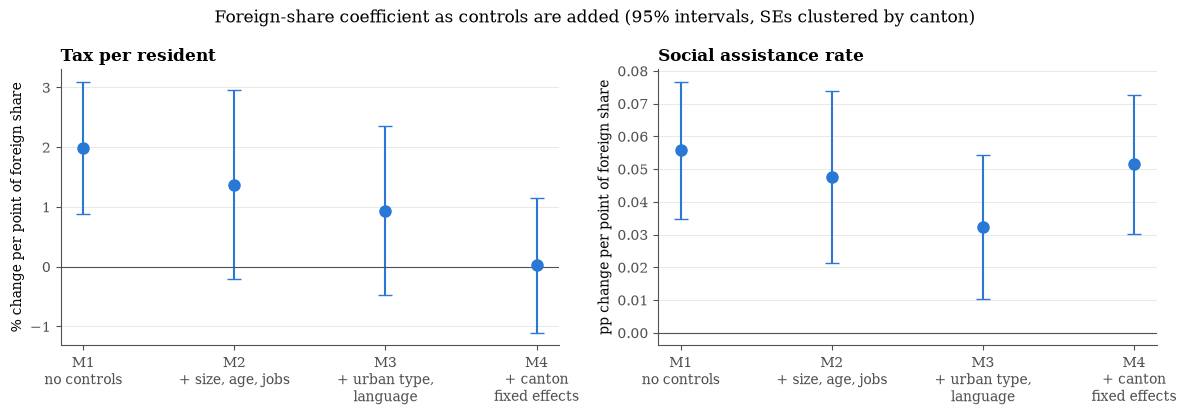

In [6]:
model_labels = ["M1\nno controls", "M2\n+ size, age, jobs",
                "M3\n+ urban type,\nlanguage", "M4\n+ canton\nfixed effects"]
panels = {
    "Tax per resident": (tax_models, 100, "% change per point of foreign share"),
    "Social assistance rate": (sa_models, 1, "pp change per point of foreign share"),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (title, (models, scale, ylabel)) in zip(axes, panels.items()):
    for i, m in enumerate(models.values()):
        coef = m.params["foreign_share"] * scale
        low, high = m.conf_int().loc["foreign_share"] * scale
        ax.errorbar(i, coef, yerr=[[coef - low], [high - coef]], fmt="o",
                    color=helpers.COLORS["urban_rural"]["urban"], capsize=5, markersize=8)
    ax.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_xticks(range(len(model_labels)), model_labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", color=helpers.INK["grid"], linewidth=0.5)

fig.suptitle("Foreign-share coefficient as controls are added (95% intervals, SEs clustered by canton)")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_coefficients_M1_M4.png")
plt.show()

**Interpretation.** As controls are added, the tax coefficient falls from about +2% per point (M1) to zero (M4), and its interval includes zero from M2 onwards. The social-assistance coefficient stays clearly positive in every model and returns to its raw size once canton fixed effects are added. This is the central contrast of the regression analysis.

## 3c. Could unobserved factors explain the SA result? (Oster 2019)
How strong would unobserved factors have to be, relative to all our controls, to make the foreign-share coefficient zero?

In [7]:
def oster(short, long, r_max, variable="foreign_share", delta=1):
    """Coefficient stability (Oster 2019, approximate formulas).

    short: model without controls (M1); long: model with all controls (M4).
    Returns the bias-adjusted coefficient (if unobserved factors are `delta` times
    as important as the observed controls) and the delta that would make it zero.
    """
    b_short, r_short = short.params[variable], short.rsquared
    b_long, r_long = long.params[variable], long.rsquared
    movement = (b_short - b_long) / (r_long - r_short)       # coefficient change per unit of R²
    b_adjusted = b_long - delta * movement * (r_max - r_long)
    delta_for_zero = b_long / (movement * (r_max - r_long))
    return b_adjusted, delta_for_zero


rows = {}
for r_label, r_max in [("R²max = 1.3 × R² of M4", min(1.3 * sa_models["M4"].rsquared, 1)),
                       ("R²max = 1 (extreme)", 1.0)]:
    b_adj, delta_zero = oster(sa_models["M1"], sa_models["M4"], r_max)
    rows[r_label] = {
        "R²max": round(r_max, 3),
        "Coefficient M4": round(sa_models["M4"].params["foreign_share"], 4),
        "Bias-adjusted coefficient (δ = 1)": round(b_adj, 4),
        "δ needed to reach zero": round(delta_zero, 1),
    }

table_oster = pd.DataFrame(rows).T
table_oster.to_csv(OUT / "table_oster_sa.csv")
table_oster

,R²max,Coefficient M4,Bias-adjusted coefficient (δ = 1),δ needed to reach zero
R²max = 1.3 × R² of M4,0.542,0.0515,0.0498,29.3
R²max = 1 (extreme),1.000,0.0515,0.0434,6.3


**Interpretation.** Adding the observed controls barely moves the SA coefficient (0.056 → 0.052) while R² rises from 0.12 to 0.42. Following Oster (2019), if unobserved factors were as important as all observed controls together (δ = 1), the bias-adjusted coefficient would be 0.050 (R²max = 1.3 × R²) or 0.043 (R²max = 1). Unobserved factors would have to be 29 times (or, in the extreme case, 6 times) as important as the observed controls to make the coefficient zero, far above the usual benchmark of δ = 1. The test uses only the models without and with all controls (M1, M4); the coefficient dips in between (M3: 0.032).

## 4. Is the relationship curved? Adding foreign share squared

,Tax (log),SA rate (pp)
foreign share,0.0329**,0.0691*
foreign share²,-0.000690***,-0.000353
turning point (%),23.8,98.0
joint p-value,0.013,0.0
R²,0.417,0.418
N,2108,1625


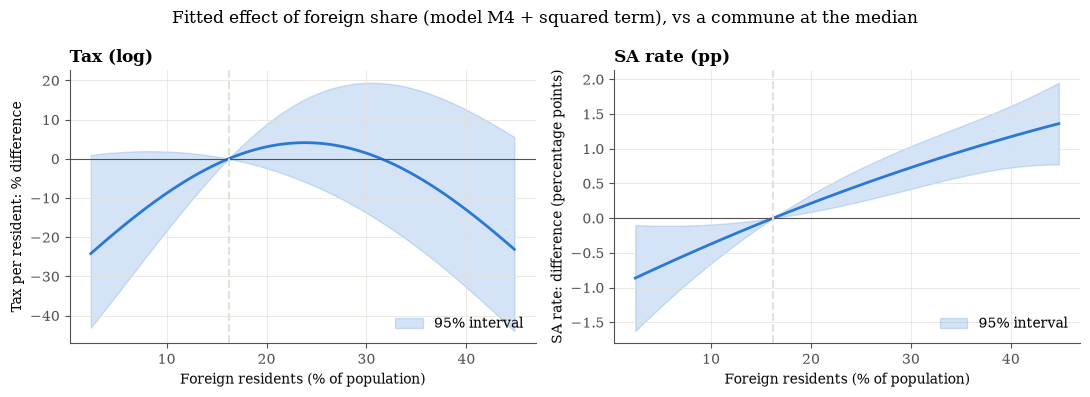

In [8]:
# Same controls as M4 (everything after the "~"), plus foreign share squared
controls = formulas["M4"].split("~")[1]
setups = {
    "Tax (log)":    ("log_tax", tax_sample, clusters),
    "SA rate (pp)": ("sa_rate", sa_sample, sa_clusters),
}

quad_models, rows = {}, {}
for label, (outcome, sample, groups) in setups.items():
    m = smf.ols(f"{outcome} ~{controls} + I(foreign_share**2)", data=sample).fit(
        cov_type="cluster", cov_kwds={"groups": groups}, use_t=True)
    quad_models[label] = m
    _ = (OUT / f"quadratic_{outcome}.txt").write_text(m.summary().as_text())

    b1 = m.params["foreign_share"]
    b2 = m.params["I(foreign_share ** 2)"]
    # Are the two foreign-share terms jointly zero?
    joint = m.f_test("foreign_share = 0, I(foreign_share ** 2) = 0")
    rows[label] = {
        "foreign share":     f"{b1:.4f}{stars(m.pvalues['foreign_share'])}",
        "foreign share²":    f"{b2:.6f}{stars(m.pvalues['I(foreign_share ** 2)'])}",
        "turning point (%)": round(-b1 / (2 * b2), 1),
        "joint p-value":     round(float(joint.pvalue), 3),
        "R²":                f"{m.rsquared:.3f}",
        "N":                 int(m.nobs),
    }

table_quad = pd.DataFrame(rows)
table_quad.to_csv(OUT / "table_quadratic.csv")
display(table_quad)

# Figure: fitted curve with a 95% confidence band, relative to a commune at the median
grid = np.linspace(df["foreign_share"].quantile(0.01), df["foreign_share"].quantile(0.99), 100)
median_fs = df["foreign_share"].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, m) in zip(axes, quad_models.items()):
    curve, lower, upper = [], [], []
    for x in grid:
        # Difference vs the median commune: b1*(x - median) + b2*(x² - median²)
        weights = pd.Series(0.0, index=m.params.index)
        weights["foreign_share"] = x - median_fs
        weights["I(foreign_share ** 2)"] = x**2 - median_fs**2
        test = m.t_test(weights.values)
        curve.append(float(test.effect[0]))
        low, high = test.conf_int()[0]
        lower.append(low)
        upper.append(high)
    curve, lower, upper = np.array(curve), np.array(lower), np.array(upper)

    if label.startswith("Tax"):
        # log points -> % difference
        curve, lower, upper = [100 * (np.exp(v) - 1) for v in (curve, lower, upper)]
        ax.set_ylabel("Tax per resident: % difference")
    else:
        ax.set_ylabel("SA rate: difference (percentage points)")

    color = helpers.COLORS["urban_rural"]["urban"]
    ax.plot(grid, curve, color=color, linewidth=2)
    ax.fill_between(grid, lower, upper, color=color, alpha=0.2, label="95% interval")
    ax.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.axvline(median_fs, color=helpers.INK["grid"], linestyle="--")
    ax.set_xlabel(helpers.LABELS["foreign_share"])
    ax.set_title(label)
    ax.legend(frameon=False, loc="lower right")
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)

fig.suptitle("Fitted effect of foreign share (model M4 + squared term), vs a commune at the median")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_quadratic_curves.png")
plt.show()

**Interpretation.** For tax, the squared term is negative and significant (−0.00069***; joint test of both foreign-share terms p = 0.013): the relationship bends, rising up to a foreign share of about 24% and falling beyond, so the zero slope in M4 averaged a rising and a falling part. The 95% band shows, however, that the *size* of the difference relative to a commune at the median foreign share is imprecisely estimated: it includes zero at almost every point, including the peak. The curvature is significant; the magnitudes are not. For social assistance, the squared term is small and insignificant and the turning point (98%) lies outside the data: the relationship is approximately linear, and the band excludes zero across the whole range. With a squared term, the joint test is the relevant one, because foreign share and its square are strongly correlated.

## 5. Does the link differ between urban, intermediate and rural communes?

,Tax (log),SA rate (pp)
urban,-0.0153*** (0.0043),0.0630*** (0.0096)
intermediate,-0.0000 (0.0057),0.0406*** (0.0100)
rural,0.0150** (0.0059),0.0482*** (0.0159)
p-value: same slope everywhere,0.0,0.038


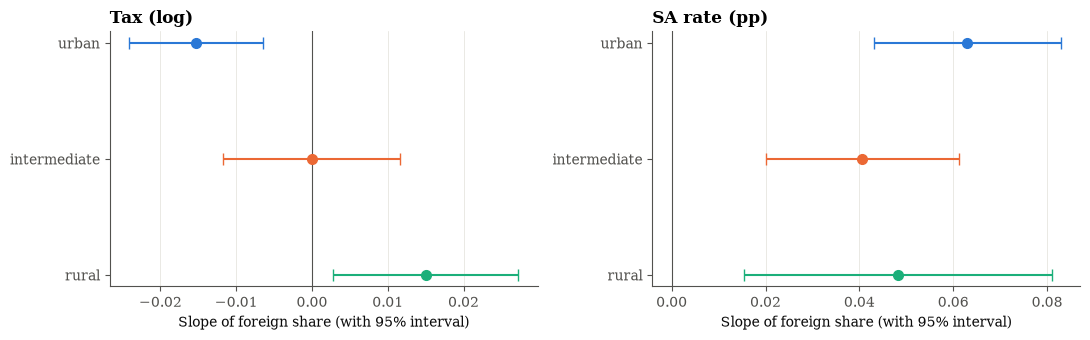

In [9]:
# M4 controls without foreign share: it re-enters as one slope per commune type
other_controls = controls.replace("foreign_share + ", "")
types = helpers.ORDER["urban_rural"]
slope_names = {t: f"C(urban_rural)[{t}]:foreign_share" for t in types}

inter_models, rows = {}, {}
for label, (outcome, sample, groups) in setups.items():
    m = smf.ols(f"{outcome} ~{other_controls} + C(urban_rural):foreign_share", data=sample).fit(
        cov_type="cluster", cov_kwds={"groups": groups}, use_t=True)
    inter_models[label] = m
    _ = (OUT / f"interaction_{outcome}.txt").write_text(m.summary().as_text())

    column = {t: f"{m.params[slope_names[t]]:.4f}{stars(m.pvalues[slope_names[t]])} "
                 f"({m.bse[slope_names[t]]:.4f})" for t in types}
    # Are the three slopes equal?
    same = m.f_test(f"{slope_names['urban']} = {slope_names['intermediate']}, "
                    f"{slope_names['intermediate']} = {slope_names['rural']}")
    column["p-value: same slope everywhere"] = round(float(same.pvalue), 3)
    rows[label] = column

table_inter = pd.DataFrame(rows)
table_inter.to_csv(OUT / "table_interaction_commune_type.csv")
display(table_inter)

# Figure: slope per commune type with its 95% confidence interval
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (label, m) in zip(axes, inter_models.items()):
    ci = m.conf_int().loc[[slope_names[t] for t in types]]
    for i, t in enumerate(types):
        ax.errorbar(m.params[slope_names[t]], i,
                    xerr=[[m.params[slope_names[t]] - ci.iloc[i, 0]],
                          [ci.iloc[i, 1] - m.params[slope_names[t]]]],
                    fmt="o", color=helpers.COLORS["urban_rural"][t], capsize=4, markersize=7)
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_yticks(range(len(types)), types)
    ax.invert_yaxis()
    ax.set_title(label)
    ax.set_xlabel("Slope of foreign share (with 95% interval)")
    ax.grid(axis="x", color=helpers.INK["grid"], linewidth=0.5)

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_interaction_commune_type.png")
plt.show()

**Interpretation.** Within cantons, the tax slope differs by commune type (equality p < 0.001): −1.5% per point in urban communes (***), zero in intermediate ones, +1.5% in rural ones (**). The opposite signs cancel out in the average M4 slope. This is consistent with two kinds of communes: high-income commuter or expat villages, and lower-income urban areas, where unobserved tax at source is also concentrated. The social-assistance slope is positive in all three types (0.041–0.063, all ***), steepest in cities (equality p = 0.038): the social-assistance association is not only an urban phenomenon. The inverted U and the urban/rural split are probably two views of the same pattern, since communes with the highest foreign shares are mostly urban.

## 5b. Which part of tax per resident moves with the foreign share?
Tax per resident = filers per resident × taxpayers per filer × tax per taxpayer. In logs the three parts add up, and so do their regression coefficients.

,All communes (M4),urban,intermediate,rural
Filers per resident,0.0001,-0.0008*,0.0002,0.0008
Taxpayers per filer,-0.0018***,-0.0032***,-0.0024***,-0.0000
Tax per taxpayer,0.0020,-0.0112**,0.0021,0.0142***
Total (tax per resident),0.0002,-0.0153***,-0.0000,0.0150**


Largest gap between the sum of the parts and the total: 6.9e-17


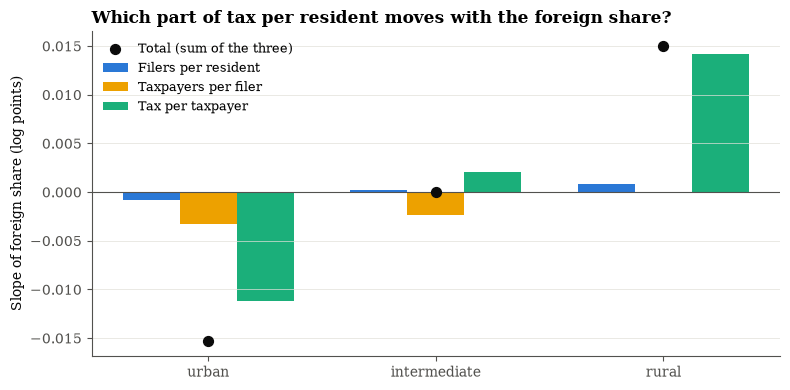

In [10]:
# The three parts of log tax per resident (they add up exactly)
tax_sample["log_filers"] = np.log(tax_sample["filers_per_capita"])
tax_sample["log_payers"] = np.log(tax_sample["payers_per_filer"])
tax_sample["log_per_payer"] = np.log(tax_sample["tax_per_taxpayer"])

parts = {
    "Filers per resident":  "log_filers",
    "Taxpayers per filer":  "log_payers",
    "Tax per taxpayer":     "log_per_payer",
    "Total (tax per resident)": "log_tax",
}

rows, slopes = {}, {}
for name, outcome in parts.items():
    linear = smf.ols(f"{outcome} ~{controls}", data=tax_sample).fit(
        cov_type="cluster", cov_kwds={"groups": clusters}, use_t=True)
    by_type = smf.ols(f"{outcome} ~{other_controls} + C(urban_rural):foreign_share",
                      data=tax_sample).fit(
        cov_type="cluster", cov_kwds={"groups": clusters}, use_t=True)
    rows[name] = {"All communes (M4)": f"{linear.params['foreign_share']:.4f}"
                                       f"{stars(linear.pvalues['foreign_share'])}"}
    for t in helpers.ORDER["urban_rural"]:
        rows[name][t] = f"{by_type.params[slope_names[t]]:.4f}{stars(by_type.pvalues[slope_names[t]])}"
    slopes[name] = {t: by_type.params[slope_names[t]] for t in helpers.ORDER["urban_rural"]}

table_split = pd.DataFrame(rows).T
table_split.to_csv(OUT / "table_tax_split.csv")
display(table_split)

# Check: the three parts add up to the total (OLS is linear, so coefficients add up too)
slopes = pd.DataFrame(slopes)
gap = (slopes.iloc[:, :3].sum(axis=1) - slopes["Total (tax per resident)"]).abs().max()
print(f"Largest gap between the sum of the parts and the total: {gap:.1e}")

# Figure: each part's slope by commune type, with the total as a black dot
part_colors = ["#2a78d6", "#eda100", "#1baf7a"]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(helpers.ORDER["urban_rural"]))
width = 0.25
for i, (name, color) in enumerate(zip(list(parts)[:3], part_colors)):
    ax.bar(x + (i - 1) * width, slopes[name], width, color=color, label=name)
ax.scatter(x, slopes["Total (tax per resident)"], color=helpers.INK["primary"],
           zorder=3, s=50, label="Total (sum of the three)")
ax.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
ax.set_xticks(x, helpers.ORDER["urban_rural"])
ax.set_ylabel("Slope of foreign share (log points)")
ax.set_title("Which part of tax per resident moves with the foreign share?")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", color=helpers.INK["grid"], linewidth=0.5)
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_tax_split.png")
plt.show()

**Interpretation.** The three parts add up exactly to the total (gap ≈ 0). In urban communes, about three quarters of the negative slope comes from lower tax per taxpayer (−0.0112**), a fifth from a lower share of filers who pay (−0.0032***), and almost nothing from the number of filers per resident (−0.0008*). Since unobserved tax at source would mainly appear as fewer filers per resident, this supports the conclusion of the tax-at-source bounds. In rural communes, the positive slope comes almost entirely from higher tax per taxpayer (+0.0142***), consistent with high-income commuter or expat villages. Across all communes, more foreign residents go with a larger share of filers who owe no federal tax (−0.0018***), consistent with the social-assistance result. These are commune-level averages over all taxpayers, Swiss and foreign.

## 5c. Does the link differ by language region or border location?
Same method as section 5. Note: all Romansh communes are in one canton, so their canton-clustered standard errors are unreliable.

language  \
                                                                        Tax (log)   
German                                                           -0.0019 (0.0061)   
French                                                            0.0021 (0.0064)   
Italian                                                        0.0093*** (0.0031)   
Romansh                                                        0.0640*** (0.0028)   
p-value: same slope everywhere                                                0.0   
N per group                     German: 1374, French: 606, Italian: 113, Roman...   
border                                                                        NaN   
inland                                                                        NaN   

                                                                                   \
                                                                     SA rate (pp)   
German                                                         0.0517*** (0.0147)   
French                                                         0.0554*** (0.0103)   
Italian                                                        0.0379*** (0.0117)   
Romansh                                                          0.0262* (0.0135)   
p-value: same slope everywhere                                               0.19   
N per group                     German: 1068, French: 466, Italian: 86, Romans...   
border                                                                        NaN   
inland                                                                        NaN   

                                                 location  \
                                                Tax (log)   
German                                                NaN   
French                                                NaN   
Italian                                               NaN   
Romansh                                               NaN   
p-value: same slope everywhere                      0.097   
N per group                     border: 265, inland: 1843   
border                                    0.0061 (0.0071)   
inland                                   -0.0021 (0.0050)   

                                                           
                                             SA rate (pp)  
German                                                NaN  
French                                                NaN  
Italian                                               NaN  
Romansh                                               NaN  
p-value: same slope everywhere                      0.076  
N per group                     border: 204, inland: 1421  
border                                  0.0261** (0.0117)  
inland                                 0.0591*** (0.0119)

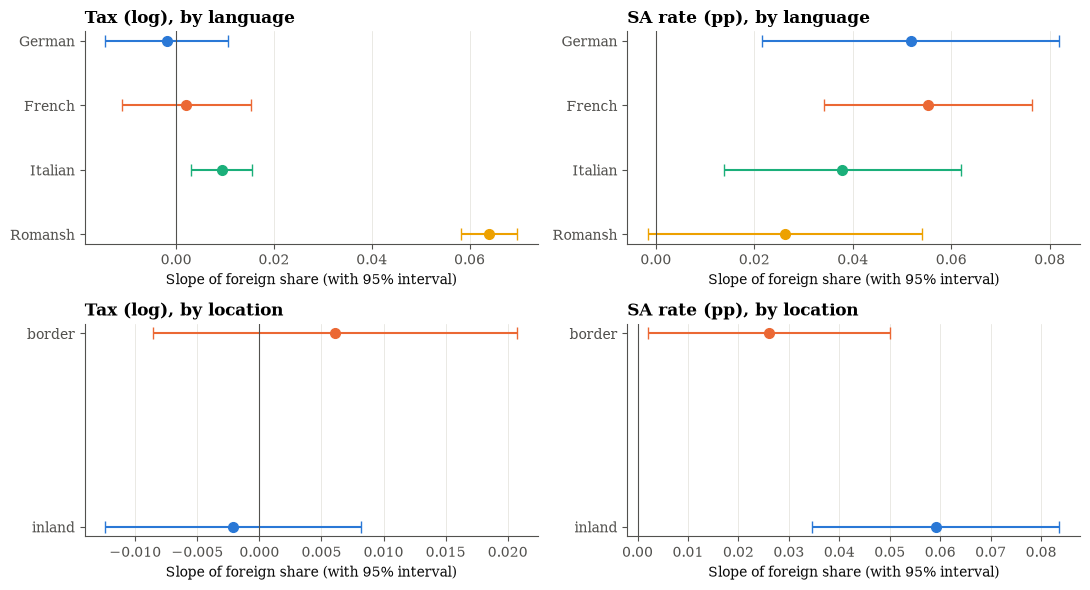

In [11]:
for sample in (tax_sample, sa_sample):
    sample["location"] = np.where(sample["border_commune"] == 1, "border", "inland")

groupings = {
    "language": (helpers.ORDER["language"], helpers.COLORS["language"]),
    "location": (["border", "inland"],
                 {"border": helpers.COLORS["urban_rural"]["intermediate"],
                  "inland": helpers.COLORS["urban_rural"]["urban"]}),
}

rows, fitted = {}, {}
for group, (levels, _) in groupings.items():
    names = {g: f"C({group})[{g}]:foreign_share" for g in levels}
    for label, (outcome, sample, groups) in setups.items():
        # One foreign-share slope per group; the group's own level is controlled for too
        m = smf.ols(f"{outcome} ~{other_controls} + C({group}) + C({group}):foreign_share",
                    data=sample).fit(cov_type="cluster", cov_kwds={"groups": groups}, use_t=True)
        fitted[(group, label)] = (m, names)
        column = {g: f"{m.params[names[g]]:.4f}{stars(m.pvalues[names[g]])} "
                     f"({m.bse[names[g]]:.4f})" for g in levels}
        equal = ", ".join(f"{names[a]} = {names[b]}" for a, b in zip(levels, levels[1:]))
        column["p-value: same slope everywhere"] = round(float(m.f_test(equal).pvalue), 3)
        column["N per group"] = ", ".join(f"{g}: {(sample[group] == g).sum()}" for g in levels)
        rows[(group, label)] = column

table_hetero = pd.DataFrame(rows)
table_hetero.to_csv(OUT / "table_heterogeneity_language_border.csv")
display(table_hetero)

# Figure: slopes with 95% intervals, rows = grouping, columns = outcome
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, (group, (levels, colors)) in enumerate(groupings.items()):
    for col, label in enumerate(setups):
        ax = axes[row, col]
        m, names = fitted[(group, label)]
        ci = m.conf_int()
        for i, g in enumerate(levels):
            coef = m.params[names[g]]
            ax.errorbar(coef, i, xerr=[[coef - ci.loc[names[g], 0]], [ci.loc[names[g], 1] - coef]],
                        fmt="o", color=colors[g], capsize=4, markersize=7)
        ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
        ax.set_yticks(range(len(levels)), levels)
        ax.invert_yaxis()
        ax.set_title(f"{label}, by {group}")
        ax.set_xlabel("Slope of foreign share (with 95% interval)")
        ax.grid(axis="x", color=helpers.INK["grid"], linewidth=0.5)

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_heterogeneity_language_border.png")
plt.show()

**Interpretation.** The social-assistance slope is similar in German-, French- and Italian-speaking communes (0.038–0.055, all ***; equality p = 0.19): the association is general rather than regional, and the strong raw Italian-speaking association of notebook 03 does not survive within cantons. It is weaker in border communes (0.026**) than inland (0.059***; p = 0.076), consistent with a larger share of employed EU workers near the border (a hypothesis). For tax, German- and French-speaking slopes are close to zero and the border difference is not significant (p = 0.097). Italian- and Romansh-speaking communes lie almost entirely in one or two cantons, so their canton-clustered standard errors rest on one or two clusters and are not reliable; their apparent significance should not be interpreted.

## 6. Which foreigners? Permit shares instead of the total foreign share

,Tax (log),SA rate (pp)
B permit holders (% of population),0.0195 (0.0135),0.0504*** (0.0158)
C permit holders (% of population),-0.0139 (0.0107),0.0420*** (0.0119)
L permit holders (% of population),0.0719 (0.0602),-0.2072** (0.0974)
"Asylum-related permits F, N, S (% of population)",-0.2702*** (0.0661),1.5127*** (0.2768)
International officials (% of population),0.0638 (0.0643),-0.1251 (0.0933)
p-value: B = C,0.145,0.699


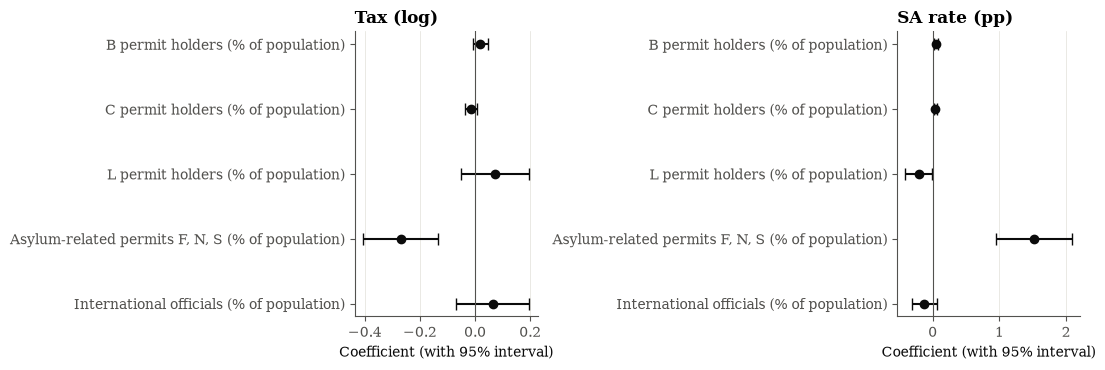

In [12]:
permits = ["share_B", "share_C", "share_L", "share_asylum", "share_intl"]

permit_models, rows = {}, {}
for label, (outcome, sample, groups) in setups.items():
    formula = f"{outcome} ~ {' + '.join(permits)} +{other_controls}"
    m = smf.ols(formula, data=sample).fit(
        cov_type="cluster", cov_kwds={"groups": groups}, use_t=True)
    permit_models[label] = m
    _ = (OUT / f"permits_{outcome}.txt").write_text(m.summary().as_text())

    column = {helpers.LABELS[p]: f"{m.params[p]:.4f}{stars(m.pvalues[p])} ({m.bse[p]:.4f})"
              for p in permits}
    column["p-value: B = C"] = round(float(m.f_test("share_B = share_C").pvalue), 3)
    rows[label] = column

table_permits = pd.DataFrame(rows)
table_permits.to_csv(OUT / "table_permit_shares.csv")
display(table_permits)

# Figure: coefficient of each permit share with its 95% interval
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (label, m) in zip(axes, permit_models.items()):
    ci = m.conf_int().loc[permits]
    ax.errorbar(m.params[permits], range(len(permits)),
                xerr=[m.params[permits] - ci[0], ci[1] - m.params[permits]],
                fmt="o", color=helpers.INK["primary"], capsize=4, markersize=6)
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_yticks(range(len(permits)), [helpers.LABELS[p] for p in permits])
    ax.invert_yaxis()
    ax.set_title(label)
    ax.set_xlabel("Coefficient (with 95% interval)")
    ax.grid(axis="x", color=helpers.INK["grid"], linewidth=0.5)

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_permit_coefficients.png")
plt.show()

**Interpretation.** B and C shares cannot be separated for tax (neither significant; equality p = 0.145), as expected given their correlation of 0.73. For social assistance, both are positive and almost equal (0.050*** and 0.042***; equality p = 0.70), so the association is not limited to recent arrivals. Short-term L permits go with lower social assistance (−0.21**). Asylum-related permits show the clearest pattern: lower tax (−0.27***) and higher social assistance (+1.51***). A coefficient above 1, together with the fact that most asylum seekers are in a separate federal statistic, suggests that this mainly reflects location (asylum housing in lower-income communes) rather than a direct effect. Coefficients are not comparable across groups because group sizes differ greatly. B and C remain significant for social assistance when asylum is held constant.

## 7. Robustness checks

In [13]:
sa_sample["log_sa"] = np.log(sa_sample["sa_rate"])

fit = helpers.fit_clustered
cell = helpers.coef_with_stars

def key_results(tax_data, sa_data, weighted=False, sa_outcome="sa_rate"):
    """Re-estimate the three key results on the given data."""
    sa = fit(f"{sa_outcome} ~{controls}", sa_data, weighted)
    quad = fit(f"log_tax ~{controls} + I(foreign_share**2)", tax_data, weighted)
    inter = fit(f"log_tax ~{other_controls} + C(urban_rural):foreign_share", tax_data, weighted)
    b1 = quad.params["foreign_share"]
    b2 = quad.params["I(foreign_share ** 2)"]
    return {
        "SA: foreign share":      cell(sa, "foreign_share"),
        "Tax: squared term":      f"{b2:.6f}{stars(quad.pvalues['I(foreign_share ** 2)'])}",
        "Tax: turning point (%)": round(-b1 / (2 * b2), 1),
        "Tax: urban slope":       cell(inter, slope_names["urban"]),
        "Tax: rural slope":       cell(inter, slope_names["rural"]),
        "N tax / N SA":           f"{int(quad.nobs)} / {int(sa.nobs)}",
    }


def without_intl(data):
    return data[data["share_intl"] <= 1]          # drop communes with >1% international officials

def without_resorts(data):
    return data[data["filers_per_capita"] <= 1]   # drop communes with more tax filers than residents


rows = {}
rows["Baseline"] = key_results(tax_sample, sa_sample)
rows["Population-weighted"] = key_results(tax_sample, sa_sample, weighted=True)
rows["Without intl-official communes"] = key_results(without_intl(tax_sample), without_intl(sa_sample))
rows["Without resort communes"] = key_results(without_resorts(tax_sample), without_resorts(sa_sample))
rows["Tax on SA sample"] = key_results(sa_sample, sa_sample)
rows["Log SA rate"] = key_results(tax_sample, sa_sample, sa_outcome="log_sa")

table_robust = pd.DataFrame(rows).T
table_robust.to_csv(OUT / "table_robustness.csv")
table_robust

,SA: foreign share,Tax: squared term,Tax: turning point (%),Tax: urban slope,Tax: rural slope,N tax / N SA
Baseline,0.0515***,-0.000690***,23.8,-0.0153***,0.0150**,2108 / 1625
Population-weighted,0.0642***,-0.000579***,17.9,-0.0186***,0.0042,2108 / 1625
Without intl-official communes,0.0608***,-0.000653**,21.3,-0.0196***,0.0124**,2050 / 1576
Without resort communes,0.0516***,-0.000672***,23.5,-0.0152***,0.0136**,2097 / 1623
Tax on SA sample,0.0515***,-0.000547**,21.6,-0.0134***,0.0075,1625 / 1625
Log SA rate,0.0186***,-0.000690***,23.8,-0.0153***,0.0150**,2108 / 1625


**Interpretation.** Three of the four key results hold in every check: the social-assistance slope (0.052–0.064***; +1.9% with log SA), the inverted U for tax (negative squared term throughout, peak 18–24%), and the negative urban tax slope (−0.013 to −0.020***). Dropping communes with many international officials (>1%) or with more tax filers than residents changes almost nothing. The positive rural tax slope is fragile: it shrinks and loses significance with population weights and on the SA sample, both of which reduce the role of the smallest villages. It describes the typical small village, not the typical resident. The tax–SA asymmetry is not due to the different samples.

## 7b. Regression diagnostics (model M4)
Residual plots, influential communes (Cook's distance) and multicollinearity (variance inflation factors), as in ISLP chapter 3.

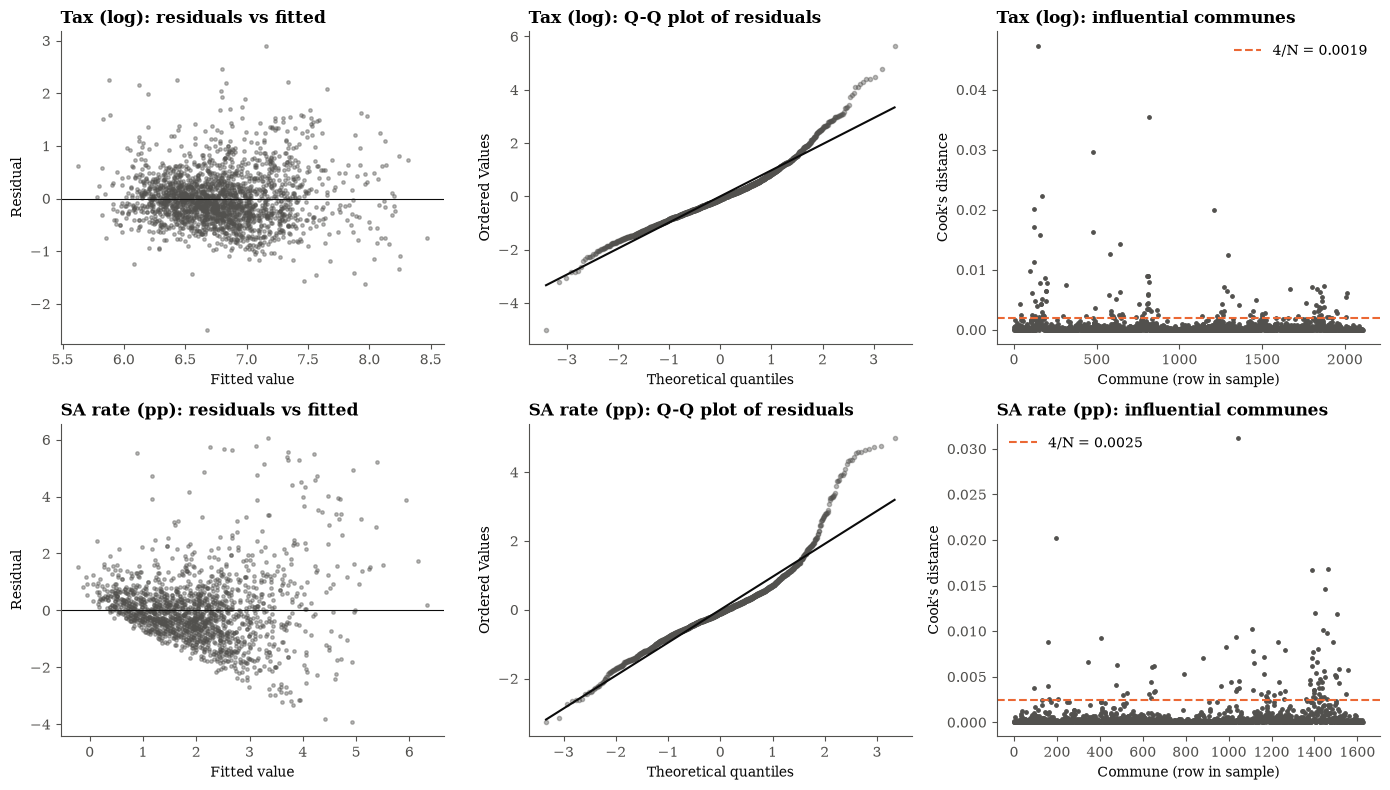

,Tax (log),SA rate (pp)
Influential communes (Cook's D > 4/N),121,87
Five most influential,"Riemenstalden, Santa Maria in Calanca, Bettingen, Hergiswil (NW), Feusisberg","Rennaz, Prévondavaux, Ederswiler, La Chaux-de-Fonds, Vernier"
"Foreign share, all communes",0.0002,0.0515***
"Foreign share, without influential",-0.0060,0.0443***


,Tax (log),SA rate (pp),Permit model
foreign_share,2.4,2.5,NaN
jobs_per_capita,1.2,1.3,NaN
log_density,3.9,3.4,NaN
log_population,2.8,2.5,NaN
share_65plus,2.7,2.8,NaN
share_B,NaN,NaN,3.2
share_C,NaN,NaN,4.1
share_L,NaN,NaN,1.6
share_asylum,NaN,NaN,1.3
share_intl,NaN,NaN,1.3


In [14]:
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_colwidth", None)

main_models = {"Tax (log)": (tax_models["M4"], tax_sample),
               "SA rate (pp)": (sa_models["M4"], sa_sample)}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
influence_rows, vif_tables = {}, {}
for row, (label, (m, sample)) in enumerate(main_models.items()):
    influence = m.get_influence()
    cooks = influence.cooks_distance[0]
    student = influence.resid_studentized_internal
    threshold = 4 / m.nobs                     # common rule of thumb for "influential"

    # (a) Residuals vs fitted values: a pattern means non-linearity or unequal variance
    ax = axes[row, 0]
    ax.scatter(m.fittedvalues, m.resid, s=6, alpha=0.4, color=helpers.INK["secondary"])
    ax.axhline(0, color=helpers.INK["primary"], linewidth=0.8)
    ax.set_xlabel("Fitted value")
    ax.set_ylabel("Residual")
    ax.set_title(f"{label}: residuals vs fitted")

    # (b) Q-Q plot: points on the line = normally distributed residuals
    ax = axes[row, 1]
    stats.probplot(student, dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=3, alpha=0.4, color=helpers.INK["secondary"])
    ax.get_lines()[1].set(color=helpers.INK["primary"])
    ax.set_title(f"{label}: Q-Q plot of residuals")

    # (c) Cook's distance: how much each commune moves the estimates
    ax = axes[row, 2]
    ax.scatter(range(len(cooks)), cooks, s=6, color=helpers.INK["secondary"])
    ax.axhline(threshold, color=helpers.COLORS["urban_rural"]["intermediate"], linestyle="--",
               label=f"4/N = {threshold:.4f}")
    ax.set_xlabel("Commune (row in sample)")
    ax.set_ylabel("Cook's distance")
    ax.set_title(f"{label}: influential communes")
    ax.legend(frameon=False)

    # Re-estimate without the influential communes
    keep = cooks <= threshold
    refit = smf.ols(m.model.formula, data=sample[keep]).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(sample.loc[keep, "canton"])[0]},
        use_t=True)
    top = sample.assign(cooks=cooks).nlargest(5, "cooks")["name"].tolist()
    influence_rows[label] = {
        "Influential communes (Cook's D > 4/N)": int((~keep).sum()),
        "Five most influential": ", ".join(top),
        "Foreign share, all communes": cell(m, "foreign_share"),
        "Foreign share, without influential": cell(refit, "foreign_share"),
    }

    # Variance inflation factors of the numeric variables (dummies left out of the table)
    exog = pd.DataFrame(m.model.exog, columns=m.model.exog_names)
    numeric_vars = ["foreign_share", "log_population", "log_density",
                    "share_under20", "share_65plus", "jobs_per_capita"]
    vif_tables[label] = pd.Series(
        {v: variance_inflation_factor(exog.values, exog.columns.get_loc(v)) for v in numeric_vars})

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_diagnostics_M4.png")
plt.show()

table_influence = pd.DataFrame(influence_rows)
table_influence.to_csv(OUT / "table_influential_communes.csv")
display(table_influence)

# VIF for the permit model too (B and C move together)
permit_exog = pd.DataFrame(permit_models["Tax (log)"].model.exog,
                           columns=permit_models["Tax (log)"].model.exog_names)
vif_tables["Permit model"] = pd.Series(
    {p: variance_inflation_factor(permit_exog.values, permit_exog.columns.get_loc(p))
     for p in permits})

table_vif = pd.DataFrame(vif_tables).round(1)
table_vif.to_csv(OUT / "table_vif.csv")
display(table_vif)

**Interpretation.** For tax, residuals show no clear pattern against fitted values; the right tail is heavier than normal (a few very high-tax communes). For social assistance, residuals fan out as the fitted rate rises (heteroskedasticity) and have a floor at zero; our canton-clustered standard errors are robust to unequal variance, and the log-SA check gave the same conclusion. About 5–6% of communes exceed the strict 4/N Cook's-distance threshold, mostly very small communes where a few taxpayers or recipients produce extreme rates; no commune comes close to the conventional level of 1. Without them, the tax coefficient stays insignificant (−0.006) and the SA coefficient stays significant (0.044***). All variance inflation factors are below 5; B and C permits have the highest in the permit model (3.2 and 4.1), which explains why their effects cannot be separated precisely.

## 7c. Where does the model go wrong? Map of the residuals
Red: higher than predicted; blue: lower than predicted; grey: commune not in the sample. Moran's I measures whether neighbouring communes have similar residuals.

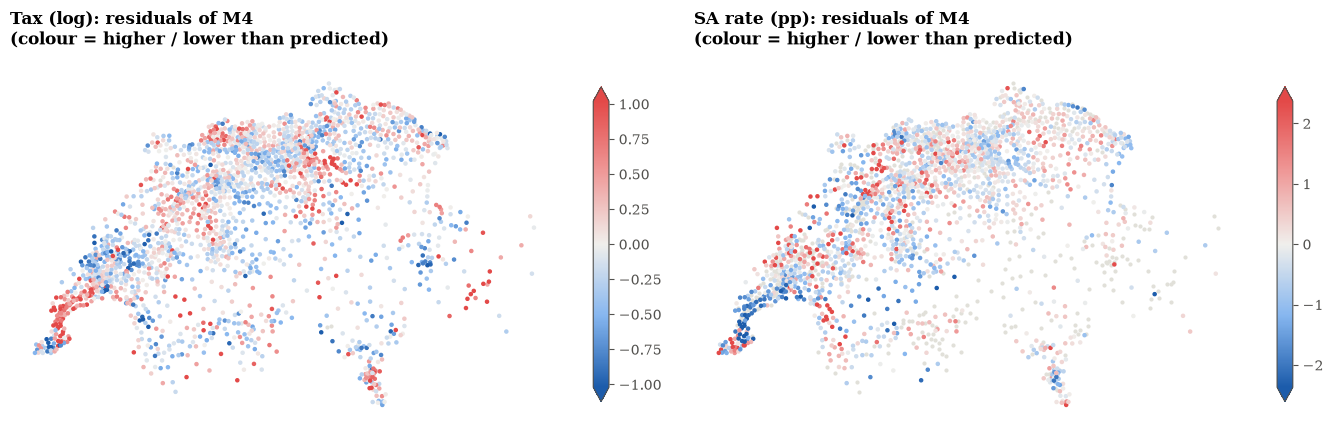

,Tax (log),SA rate (pp)
Moran's I (8 nearest neighbours),0.334,0.254
p-value (999 permutations),0.001,0.001


In [15]:
from matplotlib.colors import TwoSlopeNorm
from scipy.spatial import cKDTree


def morans_i(values, x, y, k=8, permutations=999, seed=helpers.SEED):
    """Moran's I with each commune's k nearest neighbours; p-value by random shuffling."""
    z = np.asarray(values) - np.mean(values)
    _, neighbours = cKDTree(np.column_stack([x, y])).query(np.column_stack([x, y]), k=k + 1)
    neighbours = neighbours[:, 1:]                      # drop the commune itself
    def statistic(v):
        return np.sum(v * v[neighbours].mean(axis=1)) / np.sum(v * v)
    observed = statistic(z)
    rng = np.random.default_rng(seed)
    shuffled = [statistic(rng.permutation(z)) for _ in range(permutations)]
    p_value = (1 + np.sum(np.array(shuffled) >= observed)) / (permutations + 1)
    return observed, p_value


fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
moran_rows = {}
for ax, (label, (m, sample)) in zip(axes, main_models.items()):
    resid = m.resid
    limit = np.quantile(np.abs(resid), 0.95)            # colour scale: 95% of residuals
    # Communes not in this sample, in light grey
    outside = ~df["code"].isin(sample["code"])
    ax.scatter(df.loc[outside, "x_lv95"], df.loc[outside, "y_lv95"], s=4, color=helpers.INK["grid"])
    points = ax.scatter(sample["x_lv95"], sample["y_lv95"], c=resid, s=5,
                        cmap=helpers.DIVERGING, norm=TwoSlopeNorm(0, -limit, limit))
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(f"{label}: residuals of M4\n(colour = higher / lower than predicted)")
    plt.colorbar(points, ax=ax, shrink=0.7, extend="both")

    moran, p = morans_i(resid, sample["x_lv95"], sample["y_lv95"])
    moran_rows[label] = {"Moran's I (8 nearest neighbours)": round(moran, 3),
                         "p-value (999 permutations)": round(p, 3)}

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_residual_maps.png")
plt.show()

table_moran = pd.DataFrame(moran_rows)
table_moran.to_csv(OUT / "table_morans_i.csv")
table_moran

**Interpretation.** Residuals are not randomly placed: there are local patches of communes with higher tax than predicted (Lake Geneva shore, Lake Zurich, Lugano, Engadine) next to lower-than-predicted hinterlands, and similar patches for social assistance. Moran's I with each commune's 8 nearest neighbours is 0.334 for tax and 0.254 for social assistance (p = 0.001 for both, from 999 random permutations): moderate positive spatial autocorrelation. Most patches lie within cantons, where canton-clustered standard errors already allow correlated errors; patches crossing canton borders are not fully covered, so standard errors may be somewhat too small. The patches point to missing local amenities (lake access, commuting distance); if these correlate with the foreign share, coefficients could be biased, especially for tax. A spatial regression model is left for future work; notebook 05 gives the tree models the commune coordinates.

## 7d. Only 26 cantons: wild cluster bootstrap (Cameron & Miller 2015)
With few clusters, clustered standard errors can be too small. The wild cluster bootstrap simulates our exact setting (26 cantons, null hypothesis imposed) to get reliable p-values.

In [16]:
def wild_cluster_bootstrap(model, variable, groups, reps=9999, seed=helpers.SEED, batch=1000):
    """Wild cluster bootstrap p-value (restricted, Rademacher weights; Cameron & Miller 2015).

    Tests H0: coefficient of `variable` = 0, imposing H0 when generating the
    bootstrap samples. Returns the cluster-robust t-statistic and its bootstrap p-value.
    """
    X = model.model.exog
    y = model.model.endog
    j = model.model.exog_names.index(variable)
    n, k = X.shape
    cluster_ids, codes = np.unique(groups, return_inverse=True)
    G = len(cluster_ids)
    one_hot = np.zeros((G, n))
    one_hot[codes, np.arange(n)] = 1.0                  # which commune is in which canton
    bread = np.linalg.pinv(X.T @ X)
    u = X @ bread[j]                                    # beta_j = u' y
    correction = G / (G - 1) * (n - 1) / (n - k)        # same small-sample factor as statsmodels

    def t_stats(Y):
        """Cluster-robust t-statistics of coefficient j, one per column of Y."""
        betas = bread @ (X.T @ Y)
        resid = Y - X @ betas
        scores = one_hot @ (u[:, None] * resid)         # one row per canton
        se = np.sqrt(correction * (scores**2).sum(axis=0))
        return betas[j] / se

    t_original = t_stats(y[:, None])[0]

    # Restricted model: the same regression without `variable` (imposes H0)
    X_r = np.delete(X, j, axis=1)
    fitted_r = X_r @ np.linalg.lstsq(X_r, y, rcond=None)[0]
    resid_r = y - fitted_r

    rng = np.random.default_rng(seed)
    t_boot = []
    for start in range(0, reps, batch):
        size = min(batch, reps - start)
        signs = rng.choice([-1.0, 1.0], size=(G, size))  # one random sign per canton and draw
        Y_star = fitted_r[:, None] + resid_r[:, None] * signs[codes]
        t_boot.append(t_stats(Y_star))
    t_boot = np.concatenate(t_boot)
    return t_original, np.mean(np.abs(t_boot) >= abs(t_original))


checks = [
    ("SA: foreign share (M4)",  sa_models["M4"],              "foreign_share",         sa_clusters),
    ("Tax: foreign share (M4)", tax_models["M4"],             "foreign_share",         clusters),
    ("Tax: squared term",       quad_models["Tax (log)"],     "I(foreign_share ** 2)", clusters),
    ("Tax: urban slope",        inter_models["Tax (log)"],    slope_names["urban"],    clusters),
    ("Tax: rural slope",        inter_models["Tax (log)"],    slope_names["rural"],    clusters),
    ("SA: urban slope",         inter_models["SA rate (pp)"], slope_names["urban"],    sa_clusters),
    ("SA: rural slope",         inter_models["SA rate (pp)"], slope_names["rural"],    sa_clusters),
]

rows = {}
for label, m, variable, groups in checks:
    t_value, p_boot = wild_cluster_bootstrap(m, variable, groups)
    # Check: our fast t-statistic is exactly statsmodels' clustered t-statistic
    assert abs(t_value - m.tvalues[variable]) < 1e-6, f"t-statistic mismatch for {label}"
    rows[label] = {
        "Coefficient": f"{m.params[variable]:.4f}",
        "t (clustered)": round(t_value, 2),
        "p-value (clustered, t-dist.)": round(m.pvalues[variable], 3),
        "p-value (wild cluster bootstrap)": round(p_boot, 3),
    }

table_wild = pd.DataFrame(rows).T
table_wild.to_csv(OUT / "table_wild_cluster_bootstrap.csv")
table_wild

,Coefficient,t (clustered),"p-value (clustered, t-dist.)",p-value (wild cluster bootstrap)
SA: foreign share (M4),0.0515,5.0,0.0,0.001
Tax: foreign share (M4),0.0002,0.04,0.965,0.968
Tax: squared term,-0.0007,-3.01,0.006,0.019
Tax: urban slope,-0.0153,-3.58,0.001,0.001
Tax: rural slope,0.0150,2.53,0.018,0.045
SA: urban slope,0.0630,6.53,0.0,0.0
SA: rural slope,0.0482,3.02,0.006,0.027


**Interpretation.** With only 26 cantons, the wild cluster bootstrap gives p-values that are similar for the strongest results (SA M4: 0.001; SA urban slope and tax urban slope: ≤ 0.001) and larger for the weaker ones: tax squared term 0.006 → 0.019, SA rural slope 0.006 → 0.027, tax rural slope 0.018 → 0.045. All key results remain significant at 5%, and the tax M4 coefficient stays insignificant (p = 0.968). The rural tax slope is borderline, consistent with its fragility in the robustness checks. Conventional clustered p-values were moderately optimistic, as expected with few clusters (Cameron & Miller 2015).

## 8. Tax at source: how much could the missing tax change the results?
B and L permit holders are mostly taxed at source, and that tax is not in the federal statistics we use. We add an assumed amount k (CHF per B/L resident) and re-estimate the tax results, to find how large the missing tax would have to be to change our conclusions.

,Tax: squared term,Tax: turning point (%),Tax: urban slope,Tax: rural slope
k = 0 CHF,-0.000690***,23.8,-0.0153***,0.0150**
k = 500 CHF,-0.000675***,25.9,-0.0124***,0.0177***
"k = 1,000 CHF",-0.000668***,27.7,-0.0100**,0.0200***
"k = 1,500 CHF",-0.000665***,29.3,-0.0078*,0.0220***
"k = 2,000 CHF",-0.000667***,30.7,-0.0058,0.0239***
"k = 3,000 CHF",-0.000675***,33.0,-0.0024,0.0270***
"k = 5,000 CHF",-0.000702***,36.2,0.0028,0.0320***
Same as neighbours,-0.000676***,27.1,-0.0110**,0.0194***


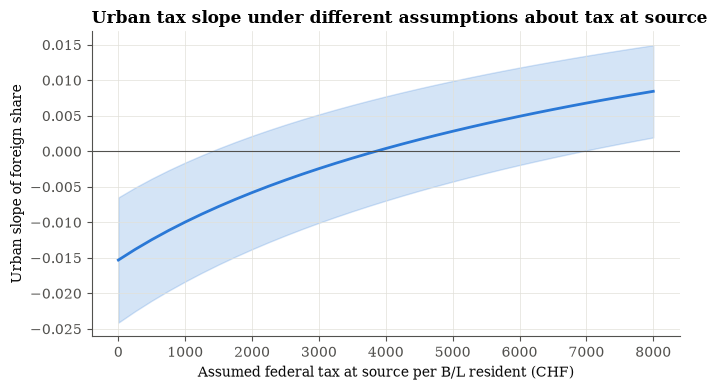

In [17]:
bl_residents = tax_sample["permit_B"] + tax_sample["permit_L"]


def tax_results(outcome_values):
    """Re-estimate the tax results with a different measure of log tax per resident."""
    data = tax_sample.assign(log_tax_adj=outcome_values)
    quad = fit(f"log_tax_adj ~{controls} + I(foreign_share**2)", data)
    inter = fit(f"log_tax_adj ~{other_controls} + C(urban_rural):foreign_share", data)
    b1 = quad.params["foreign_share"]
    b2 = quad.params["I(foreign_share ** 2)"]
    return quad, inter, {
        "Tax: squared term":      f"{b2:.6f}{stars(quad.pvalues['I(foreign_share ** 2)'])}",
        "Tax: turning point (%)": round(-b1 / (2 * b2), 1),
        "Tax: urban slope":       cell(inter, slope_names["urban"]),
        "Tax: rural slope":       cell(inter, slope_names["rural"]),
    }


# Add k CHF of federal tax per B/L resident
rows = {}
for k in [0, 500, 1000, 1500, 2000, 3000, 5000]:
    adjusted = np.log((tax_sample["tax_total"] + k * bl_residents) / tax_sample["population"])
    rows[f"k = {k:,} CHF"] = tax_results(adjusted)[2]

# Upper bound: B/L residents pay as much as the average resident of their commune
same_as_neighbours = np.log(tax_sample["tax_total"] / (tax_sample["population"] - bl_residents))
rows["Same as neighbours"] = tax_results(same_as_neighbours)[2]

table_source = pd.DataFrame(rows).T
table_source.to_csv(OUT / "table_tax_at_source_bounds.csv")
display(table_source)

# Figure: the urban slope as the assumed missing tax grows
grid_k = np.arange(0, 8001, 250)
slopes, lower, upper = [], [], []
for k in grid_k:
    adjusted = np.log((tax_sample["tax_total"] + k * bl_residents) / tax_sample["population"])
    inter = tax_results(adjusted)[1]
    ci = inter.conf_int().loc[slope_names["urban"]]
    slopes.append(inter.params[slope_names["urban"]])
    lower.append(ci[0])
    upper.append(ci[1])

fig, ax = plt.subplots(figsize=(7, 4))
urban_color = helpers.COLORS["urban_rural"]["urban"]
ax.plot(grid_k, slopes, color=urban_color, linewidth=2)
ax.fill_between(grid_k, lower, upper, color=urban_color, alpha=0.2)
ax.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
ax.set_xlabel("Assumed federal tax at source per B/L resident (CHF)")
ax.set_ylabel("Urban slope of foreign share")
ax.set_title("Urban tax slope under different assumptions about tax at source")
ax.grid(color=helpers.INK["grid"], linewidth=0.5)
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_tax_at_source_urban_slope.png")
plt.show()

**Interpretation.** Adding an assumed federal tax at source per B/L resident, the negative urban slope loses significance at about CHF 1,400 (roughly the national average federal tax per resident, CHF 1,386) and changes sign only at about CHF 3,800, about three times that average. Realistic amounts are well below the national average, because B/L residents include children, have lower incomes on average, and high earners are likely already in the ordinary statistics. Under the generous assumption that B/L residents pay as much as the average resident of their commune, the urban slope remains significant (−0.011**). The inverted U is unaffected; only its peak moves (24% → 36%). The rural slope becomes stronger. The urban result is therefore robust to plausible amounts of unobserved tax, though not to arbitrarily large ones.

## 8b. Tax competition: holding the local tax burden constant
Rich households, Swiss and foreign, can choose communes with low taxes. If communes with many foreign residents also have low tax rates, part of the foreign-share association with tax per resident could be tax competition. Here the key models are re-estimated with the commune's tax burden (income tax of a single person at a gross income of CHF 100,000 or 200,000, in %; ESTV tax calculator, 2022). With canton fixed effects, only differences between communes of the same canton count, i.e. mainly communal tax rates. The burden is partly a consequence of having rich residents (rich communes can afford lower rates), so this is a robustness check, not a main control.

In [18]:
variants = {
    "M4 (as above)": "",
    "+ tax burden at CHF 100k": " + tax_burden_100k",
    "+ tax burden at CHF 200k": " + tax_burden_200k",
}
rows = {}
for label, extra in variants.items():
    m4_tax = helpers.fit_clustered(f"log_tax ~ {helpers.M4_CONTROLS}{extra}", tax_sample)
    quad = helpers.fit_clustered(f"log_tax ~ {helpers.M4_CONTROLS}{extra} + I(foreign_share**2)", tax_sample)
    inter = helpers.fit_clustered(f"log_tax ~ {helpers.M4_OTHER_CONTROLS}{extra}"
                                  " + C(urban_rural):foreign_share", tax_sample)
    m4_sa = helpers.fit_clustered(f"sa_rate ~ {helpers.M4_CONTROLS}{extra}", sa_sample)
    row = {
        "Tax: foreign share (M4)": helpers.coef_with_stars(m4_tax, "foreign_share"),
        "Tax: foreign share squared": f"{quad.params['I(foreign_share ** 2)']:.6f}"
                                      f"{helpers.stars(quad.pvalues['I(foreign_share ** 2)'])}",
        "Tax: urban slope": helpers.coef_with_stars(inter, "C(urban_rural)[urban]:foreign_share"),
        "Tax: rural slope": helpers.coef_with_stars(inter, "C(urban_rural)[rural]:foreign_share"),
        "SA: foreign share (M4)": helpers.coef_with_stars(m4_sa, "foreign_share"),
    }
    if extra:
        burden = extra.replace(" + ", "")
        row["Tax: coefficient of the tax burden"] = helpers.coef_with_stars(m4_tax, burden)
        row["SA: coefficient of the tax burden"] = helpers.coef_with_stars(m4_sa, burden)
    rows[label] = row

table_burden = pd.DataFrame(rows).fillna("")
table_burden.to_csv(OUT / "table_tax_competition.csv")
table_burden

,M4 (as above),+ tax burden at CHF 100k,+ tax burden at CHF 200k
Tax: foreign share (M4),0.0002,0.0014,0.0014
Tax: foreign share squared,-0.000690***,-0.000566***,-0.000561***
Tax: urban slope,-0.0153***,-0.0097***,-0.0096***
Tax: rural slope,0.0150**,0.0116**,0.0115**
SA: foreign share (M4),0.0515***,0.0470***,0.0471***
Tax: coefficient of the tax burden,,-0.3610***,-0.2955***
SA: coefficient of the tax burden,,0.5380***,0.4318***


**Interpretation.** Tax competition is strong: within the same canton, one percentage point more tax burden (at CHF 100,000) goes with about 36% lower tax per resident (−0.361***), and with 0.54 percentage points more social assistance. Rich households live where taxes are low, and low-tax communes can afford their rates because they have rich residents; both directions are at work. Holding the tax burden constant, the foreign-share results remain: tax M4 still ≈ 0, the inverted U still significant, the urban slope smaller but still negative (−0.0153 → −0.0097***), the rural slope smaller but still positive (+0.0150 → +0.0116**), and the social-assistance association almost unchanged (0.0515 → 0.0470***). Tax competition thus explains part of the urban and rural contrasts (roughly a third and a quarter), not the foreign-share pattern itself. Results at CHF 200,000 are the same.

## 9. Lasso and Ridge: which variables really matter?
Variables are standardised (mean 0, SD 1), so coefficients are comparable: the change in the outcome for +1 standard deviation of the variable. The penalty is chosen by 5-fold cross-validation.

Tax (log)                   SA rate (pp)  \
                                  OLS     Lasso   Ridge          OLS   
foreign_share                   0.322   0.32100   0.271        0.679   
log_population                 -0.126  -0.12600  -0.119        0.288   
log_density                     0.276   0.27600   0.270        0.089   
share_under20                  -0.038  -0.03800  -0.040       -0.031   
share_65plus                    0.125   0.12500   0.122       -0.006   
jobs_per_capita                -0.031  -0.03100  -0.031        0.080   
foreign_share_sq               -0.307  -0.30700  -0.262       -0.166   
urban_rural_rural              -0.045  -0.04500  -0.049        0.104   
urban_rural_urban               0.013   0.01300   0.014        0.078   
language_German                -0.045  -0.04400  -0.051       -0.301   
language_Italian               -0.117  -0.11700  -0.108       -0.190   
language_Romansh               -0.023  -0.02300  -0.023       -0.030   
Canton dummies kept (of 25)    25.000  25.00000  25.000       25.000   
Penalty chosen (alpha)          0.000   0.00002  13.000        0.000   

                                               
                                Lasso   Ridge  
foreign_share                 0.49900   0.438  
log_population                0.27100   0.277  
log_density                   0.08900   0.097  
share_under20                -0.01300  -0.032  
share_65plus                  0.00000   0.004  
jobs_per_capita               0.07900   0.089  
foreign_share_sq             -0.00000   0.039  
urban_rural_rural             0.06800   0.082  
urban_rural_urban             0.07000   0.079  
language_German              -0.28600  -0.318  
language_Italian             -0.11400  -0.142  
language_Romansh             -0.01900  -0.031  
Canton dummies kept (of 25)  23.00000  25.000  
Penalty chosen (alpha)        0.00815  44.210

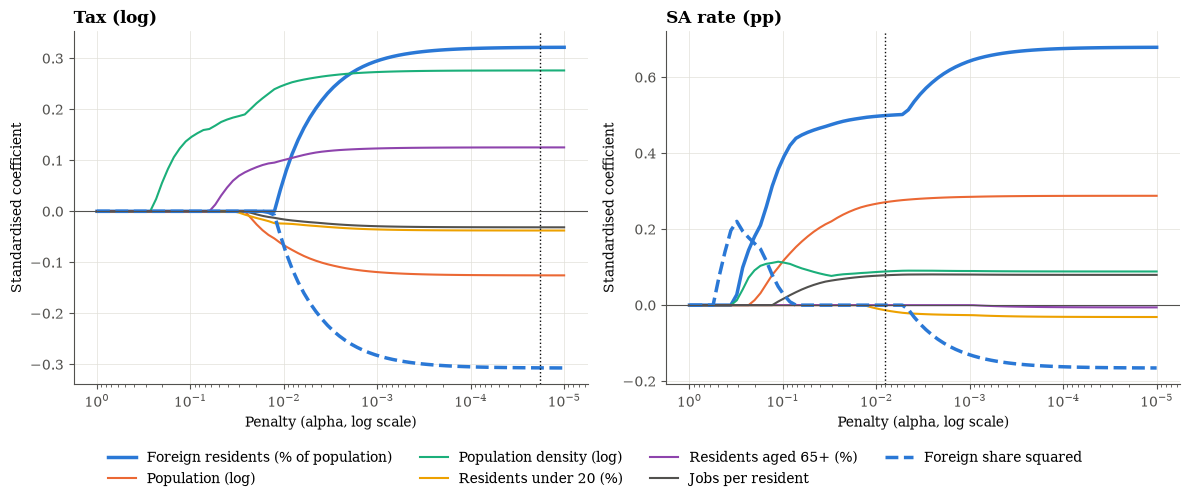

In [19]:
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, lasso_path
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

numeric = ["foreign_share", "log_population", "log_density", "share_under20",
           "share_65plus", "jobs_per_capita"]


def design_matrix(data):
    """All M4 explanatory variables + foreign share squared, with dummies as 0/1 columns."""
    X = data[numeric].copy()
    X["foreign_share_sq"] = data["foreign_share"] ** 2
    dummies = pd.get_dummies(data[["urban_rural", "language", "canton"]],
                             drop_first=True, dtype=float)
    return pd.concat([X, dummies], axis=1)


cv = KFold(n_splits=5, shuffle=True, random_state=helpers.SEED)
lasso_alphas = np.logspace(-5, 0, 80)
ridge_alphas = np.logspace(-2, 4, 80)

coef_tables, paths = {}, {}
for label, (outcome, sample, _) in setups.items():
    X = design_matrix(sample)
    y = sample[outcome]

    # Standardise first, so every variable is penalised on the same scale
    ols = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
    lasso = make_pipeline(StandardScaler(),
                          LassoCV(alphas=lasso_alphas, cv=cv, max_iter=100_000)).fit(X, y)
    ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=ridge_alphas, cv=cv)).fit(X, y)

    coefs = pd.DataFrame({"OLS": ols[-1].coef_, "Lasso": lasso[-1].coef_,
                          "Ridge": ridge[-1].coef_}, index=X.columns)
    canton_rows = coefs.index.str.startswith("canton_")
    table = coefs[~canton_rows].round(3)
    table.loc["Canton dummies kept (of 25)"] = [
        int((coefs.loc[canton_rows, m] != 0).sum()) for m in ["OLS", "Lasso", "Ridge"]]
    table.loc["Penalty chosen (alpha)"] = [0, round(lasso[-1].alpha_, 5), round(ridge[-1].alpha_, 2)]
    coef_tables[label] = table

    # Lasso path: how each coefficient shrinks as the penalty grows
    X_std = StandardScaler().fit_transform(X)
    path_alphas, path_coefs, _ = lasso_path(X_std, y - y.mean(), alphas=lasso_alphas)
    paths[label] = (path_alphas, pd.DataFrame(path_coefs.T, columns=X.columns),
                    lasso[-1].alpha_)

table_lasso = pd.concat(coef_tables, axis=1)
table_lasso.to_csv(OUT / "table_lasso_ridge.csv")
display(table_lasso)

# Figure: Lasso paths of the main variables (dummies left out to keep it readable)
main_vars = numeric + ["foreign_share_sq"]
path_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8e44ad",
               helpers.INK["secondary"], "#2a78d6"]
names = {**helpers.LABELS, "log_population": "Population (log)",
         "log_density": "Population density (log)", "foreign_share_sq": "Foreign share squared"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (label, (path_alphas, path_coefs, chosen)) in zip(axes, paths.items()):
    for var, color in zip(main_vars, path_colors):
        style = "--" if var == "foreign_share_sq" else "-"
        ax.plot(path_alphas, path_coefs[var], color=color, linestyle=style,
                linewidth=2.5 if var.startswith("foreign") else 1.5, label=names[var])
    ax.axvline(chosen, color=helpers.INK["primary"], linestyle=":", linewidth=1)
    ax.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_xscale("log")
    ax.invert_xaxis()            # strong penalty on the left, weak penalty on the right
    ax.set_xlabel("Penalty (alpha, log scale)")
    ax.set_ylabel("Standardised coefficient")
    ax.set_title(label)
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_lasso_paths.png")
plt.show()

**Interpretation.** For tax, cross-validation chooses almost no penalty: Lasso keeps every variable, including the squared term and all canton dummies, and its coefficients equal OLS. The model is not overfitted. Density is the first variable to enter the Lasso path, followed by the share aged 65+, then foreign share and its square together. For social assistance, Lasso sets the squared term, the share aged 65+ and two canton dummies to zero, confirming the linear relationship, and foreign share is the first and largest standardised coefficient, i.e. the strongest predictor of the social-assistance rate among our variables. Lasso can pick arbitrarily between strongly correlated variables (foreign share and its square at high penalties), and it gives no standard errors: it supports the OLS results but does not replace them.

## 10. Full regression tables (M1–M4, for the appendix)
Standard errors clustered by canton in parentheses. Canton dummies are included in M4 but not shown.

In [20]:
from statsmodels.iolib.summary2 import summary_col

shown = ["foreign_share", "log_population", "log_density", "share_under20",
         "share_65plus", "jobs_per_capita",
         "C(urban_rural)[T.rural]", "C(urban_rural)[T.urban]",
         "C(language)[T.German]", "C(language)[T.Italian]", "C(language)[T.Romansh]",
         "Intercept"]
readable = {**helpers.LABELS,
            "log_population": "Population (log)", "log_density": "Population density (log)",
            "C(urban_rural)[T.rural]": "Rural (vs intermediate)",
            "C(urban_rural)[T.urban]": "Urban (vs intermediate)",
            "C(language)[T.German]": "German-speaking (vs French)",
            "C(language)[T.Italian]": "Italian-speaking (vs French)",
            "C(language)[T.Romansh]": "Romansh-speaking (vs French)"}

for name, models in [("tax", tax_models), ("sa", sa_models)]:
    table = summary_col(
        list(models.values()), model_names=list(models), stars=True, float_format="%.4f",
        regressor_order=shown, drop_omitted=True,
        info_dict={"N": lambda m: f"{int(m.nobs)}",
                   "Canton fixed effects": lambda m: "yes" if "canton" in m.model.formula else "no"})
    table.tables[0].index = [readable.get(i, i) for i in table.tables[0].index]
    _ = (OUT / f"full_table_{name}.txt").write_text(table.as_text())
    _ = (OUT / f"full_table_{name}.tex").write_text(table.as_latex())
    print(f"\n{'Log tax per resident' if name == 'tax' else 'Social assistance rate'}")
    display(table.tables[0])

    # LaTeX versions of the main tables, for the paper (Overleaf)
paper_tables = {
    "table_sample_construction": table_sample,
    "table_tax_M1_M4": table_tax,
    "table_sa_M1_M4": table_sa,
    "table_quadratic": table_quad,
    "table_interaction_commune_type": table_inter,
    "table_tax_split": table_split,
    "table_heterogeneity_language_border": table_hetero,
    "table_permit_shares": table_permits,
    "table_robustness": table_robust,
    "table_tax_at_source_bounds": table_source,
    "table_wild_cluster_bootstrap": table_wild,
    "table_oster_sa": table_oster,
    "table_lasso_ridge": table_lasso,
    "table_influential_communes": table_influence,
    "table_vif": table_vif,
    "table_morans_i": table_moran,
    "table_tax_competition": table_burden,
}
for name, table in paper_tables.items():
    latex = table.to_latex(escape=True, na_rep="", float_format="%.4f")
    _ = (OUT / f"{name}.tex").write_text(latex, encoding="utf-8")
print("Saved:", len(paper_tables), "tables")


Log tax per resident


,M1,M2,M3,M4
Foreign residents (% of population),0.0199***,0.0138*,0.0094,0.0002
,(0.0054),(0.0077),(0.0069),(0.0055)
Population (log),,-0.0958*,-0.0939**,-0.0944**
,,(0.0527),(0.0431),(0.0370)
Population density (log),,0.2058***,0.2006***,0.1984***
,,(0.0366),(0.0346),(0.0343)
Residents under 20 (%),,0.0120,-0.0003,-0.0151
,,(0.0181),(0.0151),(0.0133)
Residents aged 65+ (%),,0.0225**,0.0208**,0.0277***
,,(0.0092),(0.0093),(0.0069)



Social assistance rate


,M1,M2,M3,M4
Foreign residents (% of population),0.0557***,0.0477***,0.0323***,0.0515***
,(0.0102),(0.0127),(0.0107),(0.0103)
Population (log),,0.0430,0.1244,0.2752***
,,(0.0864),(0.1056),(0.0760)
Population density (log),,0.1473,0.2459*,0.0734
,,(0.1333),(0.1316),(0.1368)
Residents under 20 (%),,0.0971***,0.0197,-0.0132
,,(0.0255),(0.0273),(0.0251)
Residents aged 65+ (%),,0.0810***,0.0818***,-0.0013
,,(0.0251),(0.0247),(0.0165)


Saved: 17 tables


## 11. Summary

| Result | Evidence | Status |
|---|---|---|
| Social assistance rises with foreign share (≈ +0.05 pp per point), within cantons | M1–M4, all robustness checks, influential communes, Lasso (strongest predictor), Oster δ = 29 (6.3 at R²max = 1) | **robust**; similar across language regions, weaker in border communes |
| Tax per resident: no linear association within cantons | M4 coefficient 0.0002, 95% interval about ±1% | **robust** |
| Tax: inverted U, bending at ≈ 18–24% foreign share | squared term significant in all checks | curvature **robust**; sizes at given foreign shares imprecise (band includes zero) |
| Tax falls with foreign share in urban communes | interaction, all checks, tax-at-source bounds (survives up to ≈ CHF 1,400 per B/L resident) | **robust**; driven mainly by lower tax per taxpayer, not fewer filers |
| Tax rises with foreign share in rural communes | interaction; driven by higher tax per taxpayer | **fragile**: small villages only |
| Permit groups | asylum share ↔ lower tax, higher SA; B and C not separable (VIF 3–4) | clear for asylum (location effect), B/C inconclusive |
| Model checks | heteroskedasticity in SA (handled by clustered SEs and log SA); VIF < 5; Moran's I 0.33 / 0.25 | residual spatial patches (lakes, resorts) are a stated limitation |

The raw puzzle of notebook 03 (foreign share goes with both higher tax and higher social assistance) is largely resolved. The tax association reflects *where* foreign residents live; within cantons it depends on context (lower income per taxpayer in cities, higher in villages) and cancels out on average. The social-assistance association holds among similar communes within the same canton, in all commune types and language regions, and would require implausibly strong unobserved factors to disappear. All results are associations between communes, not causal effects or statements about individuals. Notebook 05 tests whether flexible models find the same shapes without imposing them, and whether commune coordinates capture the remaining local patterns.